In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold,cross_val_score,train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,
                             precision_score,recall_score,f1_score,roc_curve,auc,
                             precision_recall_curve,classification_report)

In [5]:
X,y = make_classification(n_samples=1000,n_features=10,
                          weights=[0.7,0.3],random_state=42)
X_train,X_test,y_train,y_test = train_test_split(X,y,
                                                 test_size=0.3,random_state=42,stratify=y)

In [6]:
model = LogisticRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

In [7]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Precision:",round(precision_score(y_test,y_pred),3))
print("Recall :", round(recall_score(y_test, y_pred), 3))
print("F1-Score :", round(f1_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

# Stractified k-fold Cross-Validation untuk perbandiingan mod el
skf = StratifiedKFold(n_splits=5,shuffle=True,
                      random_state=42)
skor_cv = cross_val_score(model,X,y,cv=skf,scoring="f1")
print("F1-Score tiap fold:", np.round(skor_cv, 3))
print("Rata-rata F1-Score:",round(skor_cv.mean(),3),"+/-",
      round(skor_cv.std(),3))

Confusion Matrix:
 [[193  16]
 [ 20  71]]
Precision: 0.816
Recall : 0.78
F1-Score : 0.798
              precision    recall  f1-score   support

           0       0.91      0.92      0.91       209
           1       0.82      0.78      0.80        91

    accuracy                           0.88       300
   macro avg       0.86      0.85      0.86       300
weighted avg       0.88      0.88      0.88       300

F1-Score tiap fold: [0.821 0.793 0.771 0.807 0.803]
Rata-rata F1-Score: 0.799 +/- 0.017


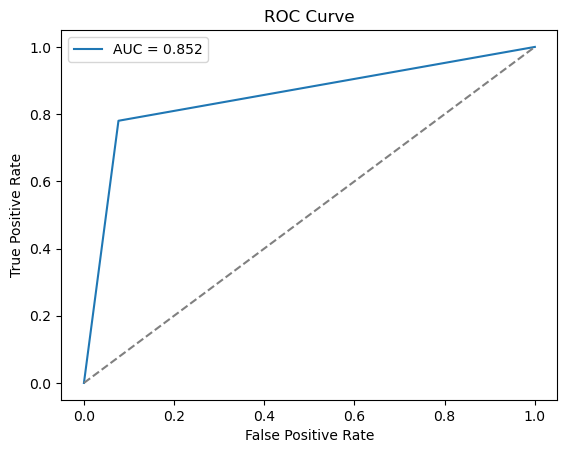

In [9]:
fpr, tpr, _ = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'--', color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.show()